# 01 · Differential binding (DiffBind)

Differential PPARα and RXRα binding between **calorie restriction (CR)** and **high-fat diet (HFD)** mouse liver,
using the filtered BAMs and MACS3 narrow peaks from nf-core/chipseq v2.1.0.

* One DiffBind object per factor (PPARA, RXRA); contrast `CR vs HFD` → **positive `Fold` = higher in CR**
  (same direction as the RNA-seq `cr_vs_hfd` contrast).
* Primary normalization: DESeq2 RLE on **background bins** (15 kb), robust to ChIP-efficiency differences between libraries.
* Sensitivity check: RLE on **reads in peaks**.
* No GRCm39 blacklist is available in DiffBind (and Ensembl contigs have no `chr` prefix), so a **greylist** is built from the matched IgG controls instead.

Kernel: `R (hnr chipseq)` (pixi env `chipseq` in `hnr-workspace/`). Run from `chipseq-workflow/analysis/` on a compute node (≥4 cores, 32 GB).
Outputs go to `../results/downstream/diffbind/`.

In [1]:
suppressPackageStartupMessages({
    library(DiffBind)
    library(tidyverse)
})
options(repr.plot.width = 7, repr.plot.height = 6, width = 160)

nf     <- "../results"                       # nf-core/chipseq outdir
ml     <- file.path(nf, "bwa/merged_library")
peaks  <- file.path(ml, "macs3/narrow_peak")
outdir <- "../results/downstream/diffbind"
dir.create(outdir, recursive = TRUE, showWarnings = FALSE)

ncores <- as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "4"))
FDR_TH <- 0.05
packageVersion("DiffBind")

[1] ‘3.16.0’

## Sample sheet
Built from the nf-core samplesheet: each ChIP replicate is paired with the IgG library of the same diet and replicate.

In [2]:
ss <- read_csv("../samplesheet.csv", show_col_types = FALSE) |>
    distinct(sample, replicate, antibody, control, control_replicate)

chip <- ss |>
    filter(!is.na(antibody)) |>
    transmute(
        SampleID   = sprintf("%s_REP%d", sample, replicate),
        Tissue     = "liver",
        Factor     = antibody,
        Condition  = sub("_.*", "", sample),
        Replicate  = replicate,
        bamReads   = file.path(ml, sprintf("%s.mLb.clN.sorted.bam", SampleID)),
        ControlID  = sprintf("%s_REP%d", control, control_replicate),
        bamControl = file.path(ml, sprintf("%s.mLb.clN.sorted.bam", ControlID)),
        Peaks      = file.path(peaks, sprintf("%s_peaks.narrowPeak", SampleID)),
        PeakCaller = "narrow"
    )
stopifnot(all(file.exists(c(chip$bamReads, chip$bamControl, chip$Peaks))))
chip |> select(SampleID, Factor, Condition, Replicate, ControlID)

SampleID,Factor,Condition,Replicate,ControlID
<chr>,<chr>,<chr>,<dbl>,<chr>
CR_PPARA_REP1,PPARA,CR,1,CR_IgG_REP1
CR_PPARA_REP2,PPARA,CR,2,CR_IgG_REP2
CR_RXRA_REP1,RXRA,CR,1,CR_IgG_REP1
CR_RXRA_REP2,RXRA,CR,2,CR_IgG_REP2
HFD_PPARA_REP1,PPARA,HFD,1,HFD_IgG_REP1
HFD_PPARA_REP2,PPARA,HFD,2,HFD_IgG_REP2
HFD_RXRA_REP1,RXRA,HFD,1,HFD_IgG_REP1
HFD_RXRA_REP2,RXRA,HFD,2,HFD_IgG_REP2


## Library QC

Read before interpreting anything below. FRiP and peak numbers vary ~10-fold **within** groups, and for PPARα the strong library is
`HFD_PPARA_REP1`: most PPARα consensus peaks come from that one sample, so ChIP efficiency is partly confounded with diet.

In [3]:
read_mqc <- function(pattern, col) {
    files <- list.files(file.path(peaks, "qc"), pattern = pattern, full.names = TRUE)
    map_dfr(files, \(f) read_tsv(f, comment = "#", col_names = c("SampleID", col), show_col_types = FALSE))
}
spp <- map_dfr(list.files(file.path(ml, "phantompeakqualtools"), "\\.spp\\.out$", full.names = TRUE),
               \(f) read_tsv(f, col_names = FALSE, col_types = cols(.default = "c"))) |>
    transmute(SampleID = sub("\\.mLb.*", "", X1), NSC = as.numeric(X9), RSC = as.numeric(X10), QualityTag = as.integer(X11))

qc <- chip |>
    select(SampleID, Factor, Condition, Replicate) |>
    left_join(read_mqc("peak_count_mqc", "Peaks"), by = "SampleID") |>
    left_join(read_mqc("FRiP_mqc", "FRiP"), by = "SampleID") |>
    left_join(spp, by = "SampleID") |>
    mutate(FRiP = round(100 * FRiP, 2), across(c(NSC, RSC), \(x) round(x, 2))) |>
    arrange(Factor, Condition, Replicate)
write_tsv(qc, file.path(outdir, "library_qc.tsv"))
qc

SampleID,Factor,Condition,Replicate,Peaks,FRiP,NSC,RSC,QualityTag
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
CR_PPARA_REP1,PPARA,CR,1,2233,0.59,1.67,7.69,2
CR_PPARA_REP2,PPARA,CR,2,2484,0.69,1.40,6.39,2
HFD_PPARA_REP1,PPARA,HFD,1,15813,8.07,1.65,2.81,2
HFD_PPARA_REP2,PPARA,HFD,2,3104,0.90,1.04,1.26,1
CR_RXRA_REP1,RXRA,CR,1,23675,9.31,1.91,2.19,2
CR_RXRA_REP2,RXRA,CR,2,5135,1.49,1.30,5.10,2
HFD_RXRA_REP1,RXRA,HFD,1,8668,2.25,1.29,2.70,2
HFD_RXRA_REP2,RXRA,HFD,2,25612,9.20,1.45,2.51,2


## Load peaks, greylist, count
`summits = 200` re-centres every consensus site to a 401 bp window around its summit; `minOverlap = 2` keeps sites called in ≥2 of the 4 libraries of a factor.

In [4]:
chroms <- read_tsv(file.path(nf, "genome/genome.fasta.sizes"), col_names = c("chr", "len"), show_col_types = FALSE)
# all contigs: DiffBind subsets this karyotype to every chromosome present in the peak files
karyo <- GenomeInfoDb::Seqinfo(seqnames = chroms$chr, seqlengths = chroms$len, genome = "GRCm39")

build <- function(factor) {
    d <- dba(sampleSheet = filter(chip, Factor == factor) |> as.data.frame())
    d$config$cores <- ncores
    d <- dba.blacklist(d, blacklist = FALSE, greylist = karyo)
    d
}
dbs <- set_names(c("PPARA", "RXRA")) |> map(build)
dbs

CR_PPARA_REP1 liver PPARA CR  1 narrow



CR_PPARA_REP2 liver PPARA CR  2 narrow



HFD_PPARA_REP1 liver PPARA HFD  1 narrow



HFD_PPARA_REP2 liver PPARA HFD  2 narrow



Counting control reads for greylist...



Building greylist: ../results/bwa/merged_library/CR_IgG_REP1.mLb.clN.sorted.bam



... (31 outputs left out)

Master greylist: 4867 ranges, 13710444 bases



Removed: 9739 of 63090 intervals.



Removed: 4794 merged (of 38660) and 2729 (of 14463) consensus.



$PPARA
4 Samples, 3269 sites in matrix (15109 total):
              ID Tissue Factor Condition Replicate Intervals
1  CR_PPARA_REP1  liver  PPARA        CR         1      1818
2  CR_PPARA_REP2  liver  PPARA        CR         2      1896
3 HFD_PPARA_REP1  liver  PPARA       HFD         1     13985
4 HFD_PPARA_REP2  liver  PPARA       HFD         2      2371

$RXRA
4 Samples, 11734 sites in matrix (33866 total):
             ID Tissue Factor Condition Replicate Intervals
1  CR_RXRA_REP1  liver   RXRA        CR         1     19937
2  CR_RXRA_REP2  liver   RXRA        CR         2      3832
3 HFD_RXRA_REP1  liver   RXRA       HFD         1      7825
4 HFD_RXRA_REP2  liver   RXRA       HFD         2     21757


PPARA



[1] 15109  3269  1219   439


RXRA



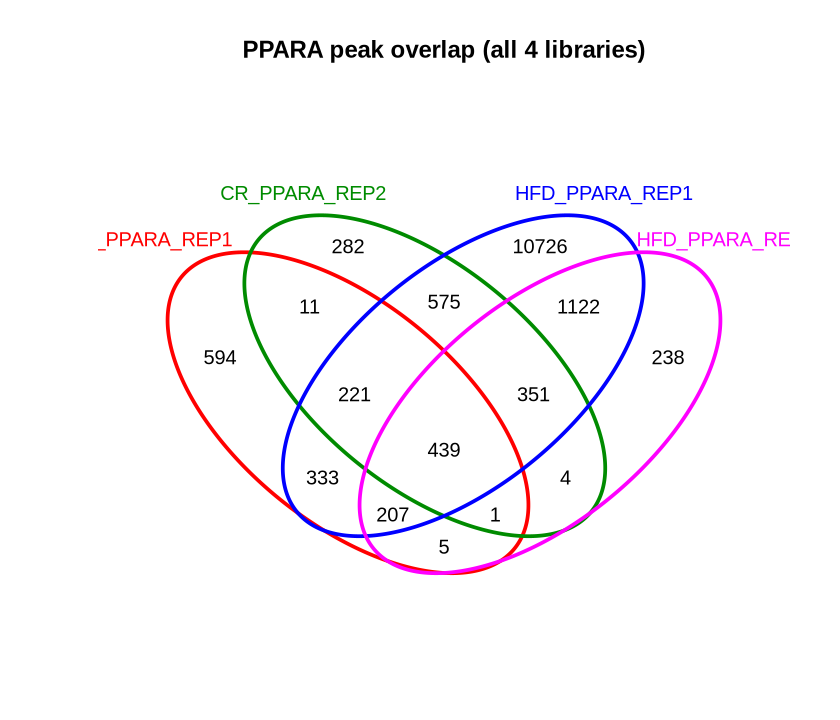

[1] 33866 11734  5127  2001


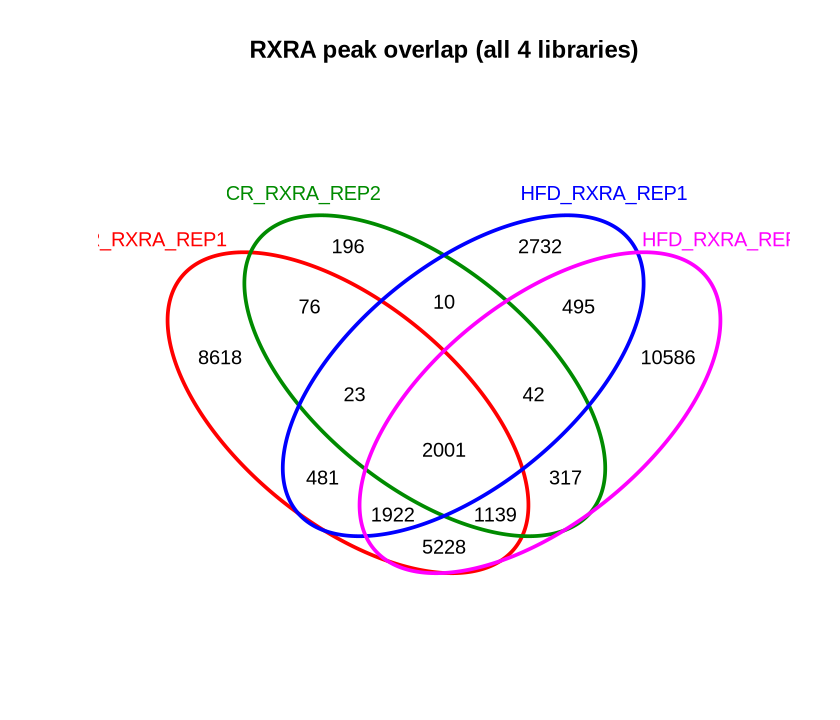

In [5]:
for (f in names(dbs)) {
    message(f)
    dba.plotVenn(dbs[[f]], mask = dbs[[f]]$masks$All, main = paste(f, "peak overlap (all 4 libraries)"))
    print(dba.overlap(dbs[[f]], mode = DBA_OLAP_RATE))   # sites in >=1, >=2, >=3, 4 libraries
}

In [6]:
dbs <- map(dbs, \(d) dba.count(d, summits = 200, minOverlap = 2, bParallel = TRUE))
map(dbs, dba.show) |> bind_rows(.id = "Factor") |> select(Factor, ID, Condition, Replicate, Reads, FRiP)

Computing summits...



Re-centering peaks...



Computing summits...



Re-centering peaks...



,Factor,ID,Condition,Replicate,Reads,FRiP
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
1...1,PPARA,CR_PPARA_REP1,CR,1,3239190,0.01
2...2,PPARA,CR_PPARA_REP2,CR,2,4377036,0.01
3...3,PPARA,HFD_PPARA_REP1,HFD,1,4429886,0.03
4...4,PPARA,HFD_PPARA_REP2,HFD,2,8907404,0.01
1...5,RXRA,CR_RXRA_REP1,CR,1,3186751,0.06
2...6,RXRA,CR_RXRA_REP2,CR,2,5473109,0.02
3...7,RXRA,HFD_RXRA_REP1,HFD,1,5717611,0.03
4...8,RXRA,HFD_RXRA_REP2,HFD,2,11959710,0.05


## Normalize, contrast, analyze
Primary: RLE on background bins. Sensitivity: RLE on reads in consensus peaks.

In [7]:
run_db <- function(d, mode) {
    d <- if (mode == "background") {
        dba.normalize(d, normalize = DBA_NORM_NATIVE, background = TRUE, method = DBA_DESEQ2)
    } else {
        dba.normalize(d, normalize = DBA_NORM_RLE, library = DBA_LIBSIZE_PEAKREADS, background = FALSE, method = DBA_DESEQ2)
    }
    d <- dba.contrast(d, contrast = c("Condition", "CR", "HFD"), minMembers = 2)
    dba.analyze(d, method = DBA_DESEQ2, bBlacklist = FALSE, bGreylist = FALSE)
}
res_bg <- map(dbs, run_db, mode = "background")
res_rip <- map(dbs, run_db, mode = "peakreads")
map(res_bg, \(d) dba.normalize(d, bRetrieve = TRUE, method = DBA_DESEQ2)$norm.factors)

Generating background bins...



Computing results names...



Analyzing...



gene-wise dispersion estimates



mean-dispersion relationship



final dispersion estimates



... (13 outputs left out)

gene-wise dispersion estimates



mean-dispersion relationship



final dispersion estimates



$PPARA
 CR_PPARA_REP1  CR_PPARA_REP2 HFD_PPARA_REP1 HFD_PPARA_REP2 
     0.6943474      0.9372323      0.8475765      1.8661975 

$RXRA
 CR_RXRA_REP1  CR_RXRA_REP2 HFD_RXRA_REP1 HFD_RXRA_REP2 
    0.5154448     1.0487821     0.9450756     2.1406171

In [8]:
report <- function(d) {
    dba.report(d, th = 1, bCounts = TRUE, method = DBA_DESEQ2) |>
        as.data.frame() |>
        rownames_to_column("site") |>
        rename(chr = seqnames) |>
        mutate(chr = as.character(chr)) |>
        arrange(FDR)
}
tab_bg  <- map(res_bg, report)
tab_rip <- map(res_rip, report)

summ <- function(tabs, label) map_dfr(tabs, \(t) tibble(
    sites = nrow(t),
    sig = sum(t$FDR < FDR_TH),
    CR_gained = sum(t$FDR < FDR_TH & t$Fold > 0),
    HFD_gained = sum(t$FDR < FDR_TH & t$Fold < 0)), .id = "Factor") |> mutate(normalization = label)
bind_rows(summ(tab_bg, "background (primary)"), summ(tab_rip, "reads-in-peaks")) |> arrange(Factor)

Factor,sites,sig,CR_gained,HFD_gained,normalization
<chr>,<int>,<int>,<int>,<int>,<chr>
PPARA,3265,0,0,0,background (primary)
PPARA,3265,8,8,0,reads-in-peaks
RXRA,11664,0,0,0,background (primary)
RXRA,11664,0,0,0,reads-in-peaks


### Sensitivity: agreement between normalizations
Sites are identical in both runs (same counts), so they can be matched by coordinates.

In [9]:
agree <- map2_dfr(tab_bg, tab_rip, \(a, b) {
    m <- inner_join(select(a, chr, start, end, Fold_bg = Fold, FDR_bg = FDR),
                    select(b, chr, start, end, Fold_rip = Fold, FDR_rip = FDR), by = c("chr", "start", "end"))
    tibble(sig_bg = sum(m$FDR_bg < FDR_TH), sig_rip = sum(m$FDR_rip < FDR_TH),
           sig_both = sum(m$FDR_bg < FDR_TH & m$FDR_rip < FDR_TH),
           same_sign_both = sum(m$FDR_bg < FDR_TH & m$FDR_rip < FDR_TH & sign(m$Fold_bg) == sign(m$Fold_rip)),
           fold_spearman = cor(m$Fold_bg, m$Fold_rip, method = "spearman"))
}, .id = "Factor")
agree

Factor,sig_bg,sig_rip,sig_both,same_sign_both,fold_spearman
<chr>,<int>,<int>,<int>,<int>,<dbl>
PPARA,0,8,0,0,0.9527220
RXRA,0,0,0,0,0.8949336


## Plots (primary normalization)

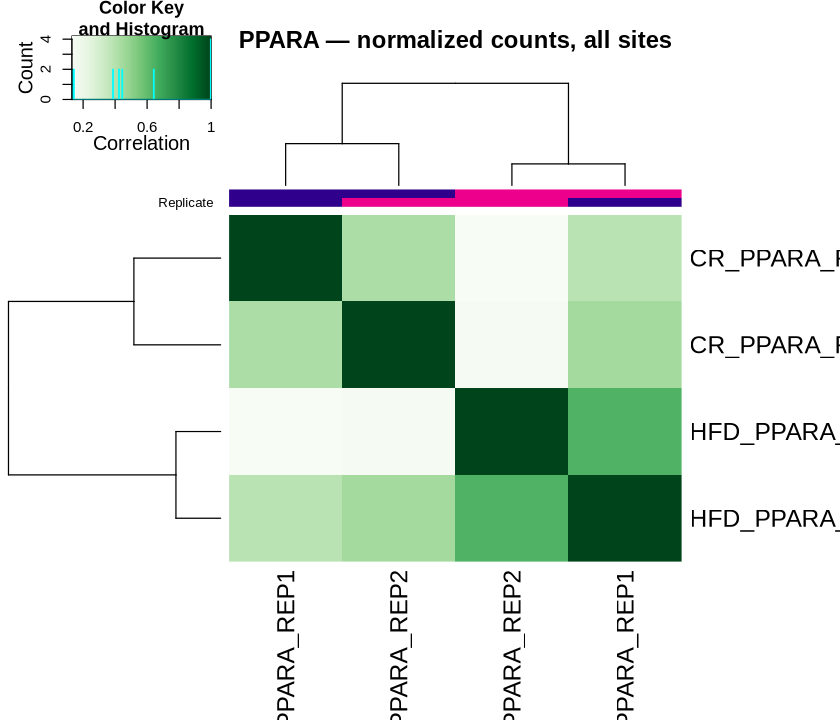

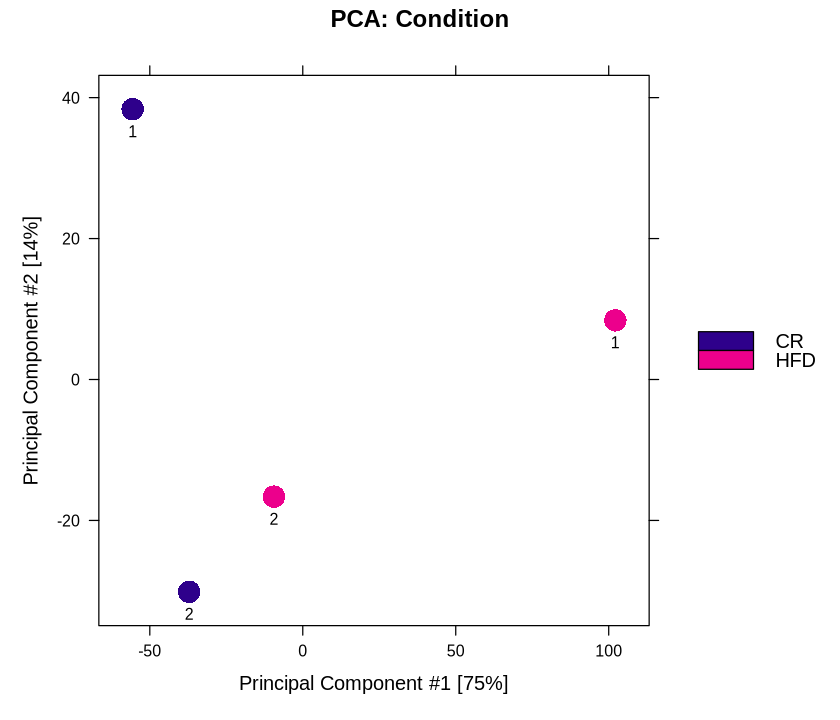

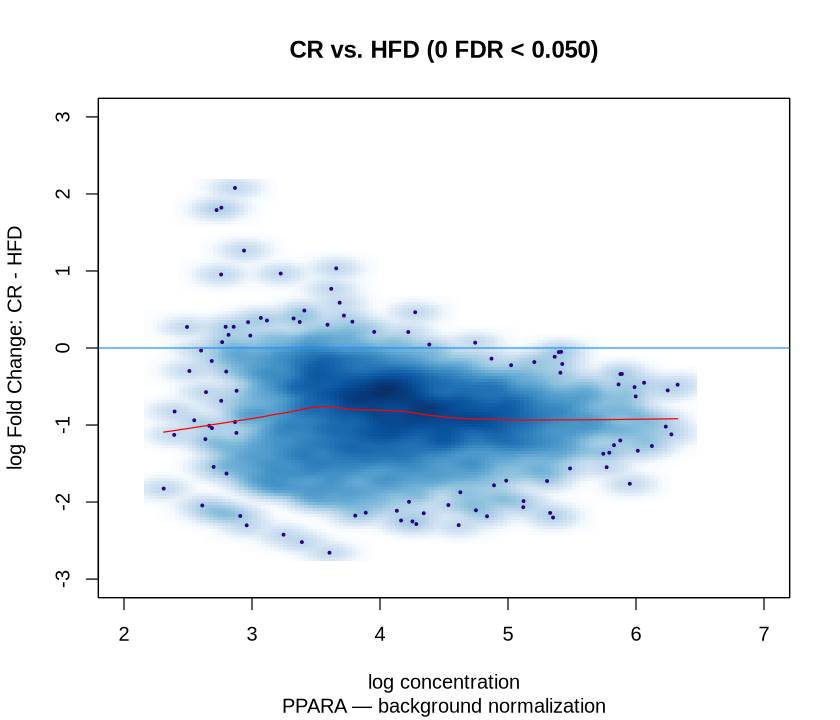

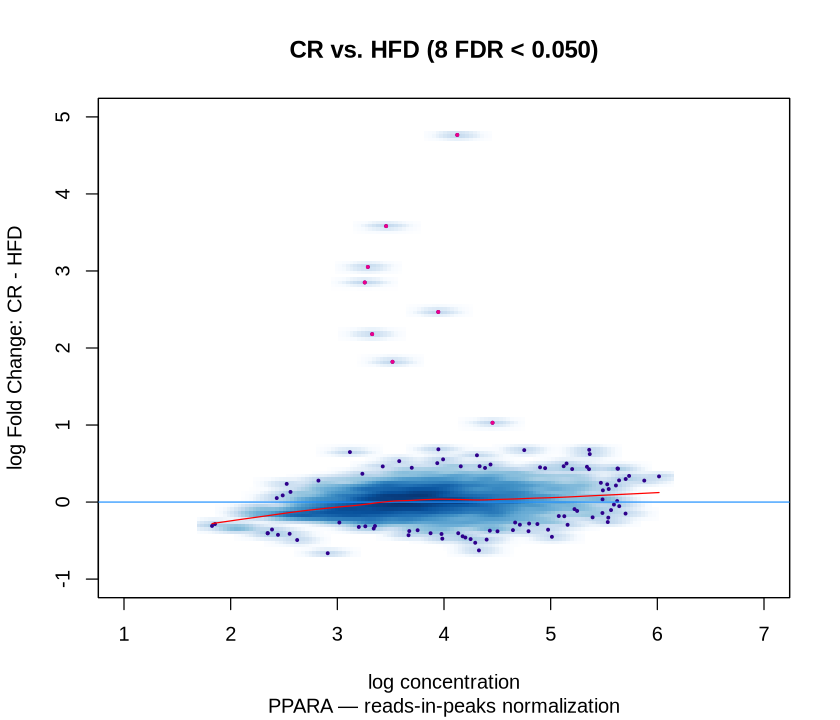

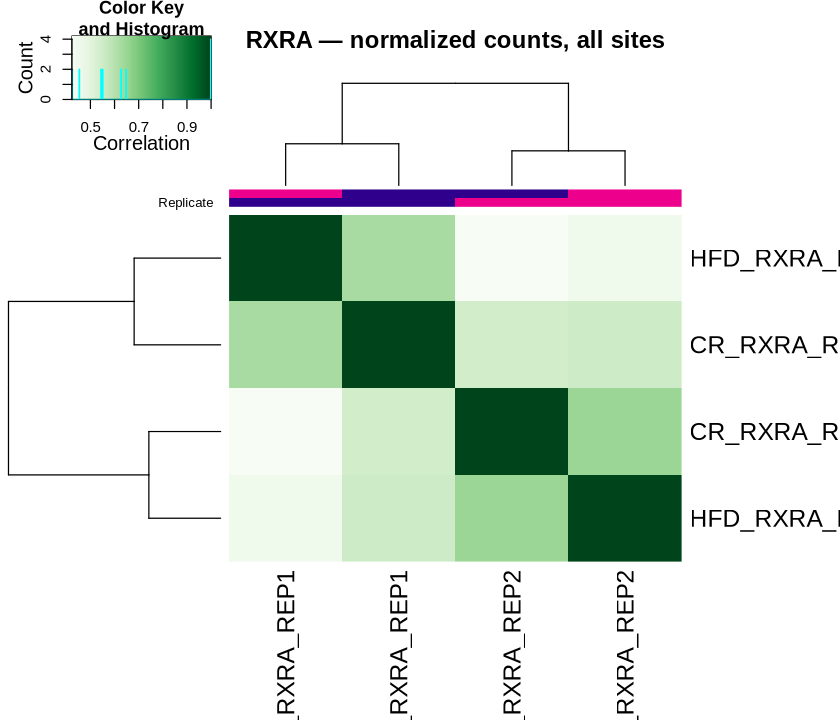

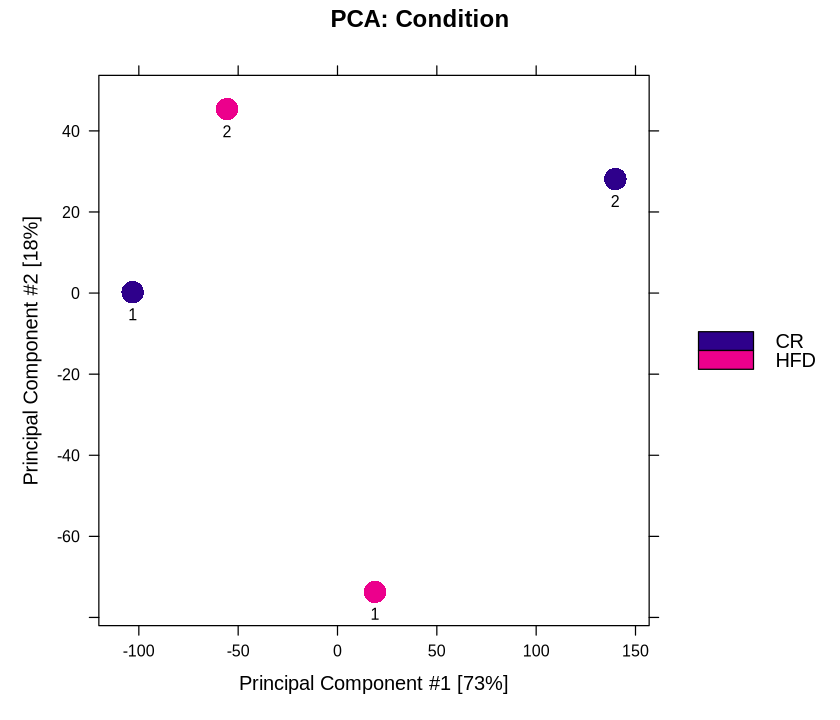

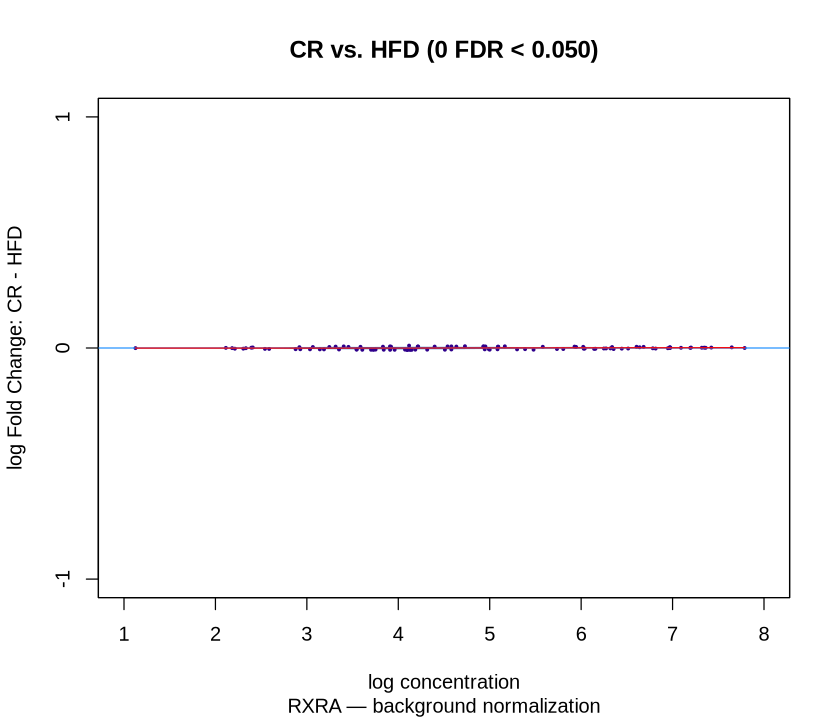

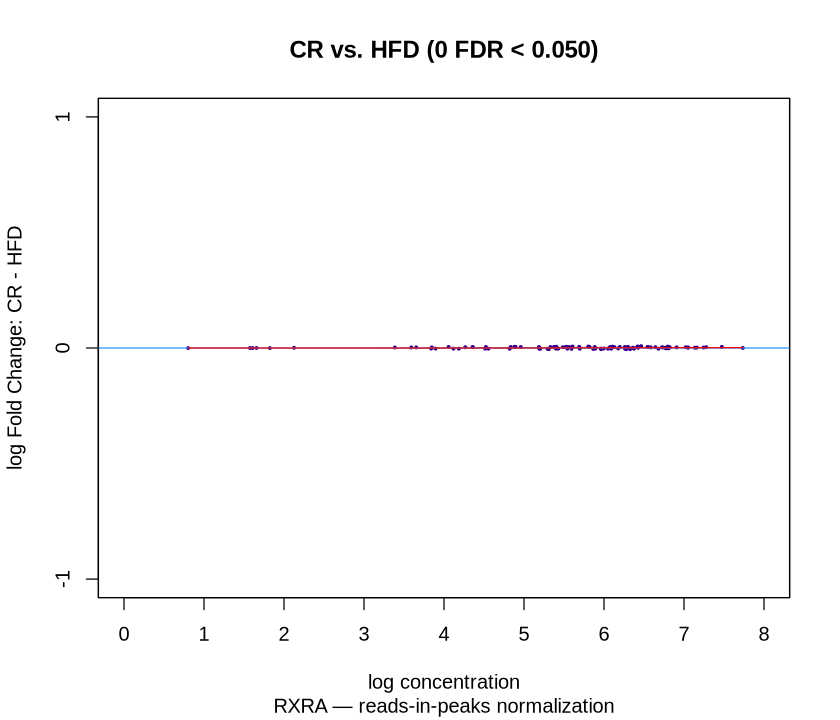

In [10]:
for (f in names(res_bg)) {
    d <- res_bg[[f]]
    dba.plotHeatmap(d, correlations = TRUE, score = DBA_SCORE_NORMALIZED, main = paste(f, "— normalized counts, all sites"))
    dba.plotPCA(d, attributes = DBA_CONDITION, label = DBA_REPLICATE, score = DBA_SCORE_NORMALIZED)
    dba.plotMA(d, th = FDR_TH, method = DBA_DESEQ2)
    title(sub = paste(f, "— background normalization"))
    dba.plotMA(res_rip[[f]], th = FDR_TH, method = DBA_DESEQ2)
    title(sub = paste(f, "— reads-in-peaks normalization"))
    if (sum(tab_bg[[f]]$FDR < FDR_TH) > 0) dba.plotVolcano(d, th = FDR_TH, method = DBA_DESEQ2)
}

In [11]:
for (f in names(res_bg)) {
    pdf(file.path(outdir, sprintf("%s.diffbind_plots.pdf", f)), width = 7, height = 6)
    d <- res_bg[[f]]
    dba.plotHeatmap(d, correlations = TRUE, score = DBA_SCORE_NORMALIZED)
    dba.plotPCA(d, attributes = DBA_CONDITION, label = DBA_REPLICATE, score = DBA_SCORE_NORMALIZED)
    dba.plotMA(d, th = FDR_TH, method = DBA_DESEQ2)
    dba.plotMA(res_rip[[f]], th = FDR_TH, method = DBA_DESEQ2)
    if (sum(tab_bg[[f]]$FDR < FDR_TH) > 0) dba.plotVolcano(d, th = FDR_TH, method = DBA_DESEQ2)
    invisible(dev.off())
}

## Export

| File | Contents |
|---|---|
| `{F}.db_all.tsv` | every consensus site (primary normalization), sorted by FDR, plus reads-in-peaks `Fold_rip`/`FDR_rip` |
| `{F}.db_sig.tsv` | FDR < 0.05 subset |
| `{F}.consensus.bed` | all consensus sites (401 bp, summit-centred), BED6 with signed Fold as score |
| `{F}.dba.rds` | the analysed DBA object (primary normalization) |

Coordinates in the TSVs are 1-based closed (GRanges); the BED is 0-based half-open.

In [12]:
for (f in names(tab_bg)) {
    t <- tab_bg[[f]] |>
        left_join(select(tab_rip[[f]], chr, start, end, Fold_rip = Fold, FDR_rip = FDR), by = c("chr", "start", "end")) |>
        mutate(site_id = sprintf("%s_%s:%d-%d", f, chr, start, end), factor = f, .before = 1) |>
        select(-site)
    write_tsv(t, file.path(outdir, sprintf("%s.db_all.tsv", f)))
    write_tsv(filter(t, FDR < FDR_TH), file.path(outdir, sprintf("%s.db_sig.tsv", f)))
    t |> transmute(chr, start = start - 1, end, name = site_id, score = round(Fold, 3), strand = ".") |>
        write_tsv(file.path(outdir, sprintf("%s.consensus.bed", f)), col_names = FALSE)
    saveRDS(res_bg[[f]], file.path(outdir, sprintf("%s.dba.rds", f)))
}
list.files(outdir)

[1] "library_qc.tsv"           "PPARA.consensus.bed"      "PPARA.db_all.tsv"         "PPARA.db_sig.tsv"         "PPARA.dba.rds"           
 [6] "PPARA.diffbind_plots.pdf" "RXRA.consensus.bed"       "RXRA.db_all.tsv"          "RXRA.db_sig.tsv"          "RXRA.dba.rds"            
[11] "RXRA.diffbind_plots.pdf"

In [13]:
tab_bg |> map(\(t) head(select(t, chr, start, end, Conc_CR, Conc_HFD, Fold, FDR), 10))

,chr,start,end,Conc_CR,Conc_HFD,Fold,FDR
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,5,44399014,44399414,0.0000000,4.605350,-2.657623,0.2045903
2,7,65559110,65559510,0.0000000,4.389860,-2.519419,0.2045903
3,10,23798435,23798835,0.0000000,4.246458,-2.423230,0.2045903
4,10,21335851,21336251,0.0000000,3.958552,-2.301688,0.2045903
5,17,17081191,17081591,0.9808932,5.555397,-2.299534,0.2045903
6,13,27896136,27896536,0.0000000,5.143072,-2.239165,0.2045903
7,4,149388979,149389379,0.3260614,5.236332,-2.285390,0.2045903
8,11,42089354,42089754,0.0000000,3.908183,-2.180704,0.2045903
9,8,39279580,39279980,0.3260614,5.205237,-2.251327,0.2045903


## Notes for interpretation

* With n = 2 per group and one low-quality library per group (see the QC table), significance here is driven largely by the
  stronger replicate. Treat sites as candidates. Sites significant under **both** normalizations with the same sign (table above) are the
  most defensible set.
* If a factor yields few or no FDR < 0.05 sites, that is the honest answer for this dataset. The full ranked table is still exported
  for downstream ranking and integration in `02_peak_annotation.ipynb`.

In [14]:
writeLines(capture.output(sessionInfo()), file.path(outdir, "R_sessionInfo.log"))
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Red Hat Enterprise Linux 9.7 (Plow)

Matrix products: default
BLAS/LAPACK: /users/j/a/jaileru/hepatic-nutrient-regulation/hnr-workspace/.pixi/envs/chipseq/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C               LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8     LC_MONETARY=en_US.UTF-8   
 [6] LC_MESSAGES=en_US.UTF-8    LC_PAPER=en_US.UTF-8       LC_NAME=C                  LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/New_York
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] lubridate_1.9.5             forcats_1.0.1               stringr_1.6.0               dplyr_1.2.1                 purrr_1.2.2                
 [6] readr_2.2.0             